## Windows

### Frequency response

In [ ]:
import matplotlib.pyplot as plt
import numpy as np

hamming = np.hamming(100)

fig,ax = plt.subplots(1,2)
ax[0].plot(hamming)
ax[0].set_title('Hamming window in time domain')
ax[0].set_xlabel('Samples')
ax[0].set_ylabel('Amplitude')

A = np.fft.fft(hamming, 2048) / 25.5
mag = np.abs(np.fft.fftshift(A))
freq = np.linspace(-0.5, 0.5, len(A))
response = 20 * np.log10(mag)
response = np.clip(response, -100, 100)
ax[1].plot(freq, response)
ax[1].set_title("Frequency response of Hamming window")
ax[1].set_ylabel("Magnitude [dB]")
ax[1].set_xlabel("Normalized frequency [cycles per sample]")
ax[1].axis('tight')

fig.tight_layout()
fig.set_size_inches(10,4)
plt.show()

### Windowing function properties

In [ ]:
import pandas as pd
from scipy.signal import get_window

def compute_mainlobe_width(spectrum):
    """
    computes mainlobe width from spectrum
    
    assumes the mainlobe starts at 0, that spectrum size is odd, and that 
    the spectrum is real-valued (half of the frequencies)
    
    returns the number of samples of full mainlobe (not just half)
    """
    abs_spectrum = np.abs(spectrum)
    current_value = abs_spectrum[0]
    for ind, next_value in enumerate(abs_spectrum):
        if next_value > current_value:
            break
        else:
            current_value = next_value        
    return 2 * ind - 1

def compute_sidelobe_level(spectrum):
    """
    computes sidelobe level from spectrum

    assumes the mainlobe starts at 0, that spectrum size is odd, and that 
    the spectrum is real-valued (half of the frequencies)
    
    returns the level of sidelobes in dB 
    """
    mainlobe_width = compute_mainlobe_width(spectrum)
    
    ind = int((mainlobe_width - 1) / 2)
    
    abs_spectrum = np.abs(spectrum)
    
    return 20 * np.log10(abs_spectrum[ind:].max() / abs_spectrum.max())

props = {}
for window in ['boxcar', 'hanning', 'hamming', 'blackman', 'blackmanharris',10,11,12,13,20,50]:
    m = 513
    w = get_window(window, m)
    n = 4096
    w_fft = np.fft.rfft(w, n)
    freqs = np.fft.rfftfreq(n, d=1/m)
    width = compute_mainlobe_width(w_fft)
    width_bins = width * m / n
    level = compute_sidelobe_level(w_fft)
    props[window] = {'mainlobe width (bins)': width_bins,
                    'sidelobe level (dB)': level}
df = pd.DataFrame(props).transpose()
df

### Validation

In [8]:
import sys
sys.path.append('..')

from wavelet_transform.wpt import transform as wpt
from wavelet_transform.test import plotting as test_plot
from wavelet_transform.wpt import inverse_transform as inv

import numpy as np
import pywt
import matplotlib.pyplot as plt

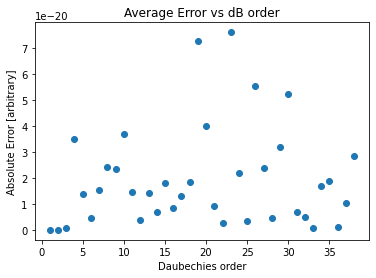

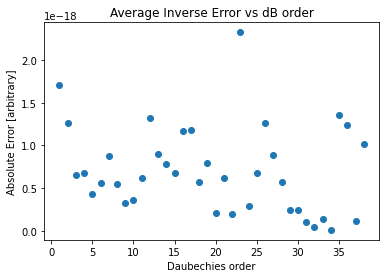

In [11]:
time = np.linspace(0,10,int(1e5))
data = np.sin(time)

for i in range(1500,1501):
    num = f'{i}'
    file = r'C:\Users\maxau\OneDrive\Codes\WPT-Cavitation\docs\OneDrive_2023-04-25\PCD data - Test ID5 - 26-09-2022 - 2MHz - 34Wcm-2\C2test0'+num+'.txt'
    try:
        dfb=pd.read_csv(file, sep=',', header=None)  
    except FileNotFoundError:
        continue
    data = dfb.iloc[:,-1]
    time = dfb.iloc[:,-2]

test_levels = [10]
test_wavelets = [f'db{i}' for i in range(1,39)]

errors = []
rec_errors = []
for wavelet in test_wavelets:
    for levels in test_levels:
        # transform
        pywp_object = pywt.WaveletPacket(data,wavelet,maxlevel = levels)
        transform_object = wpt.dwpt(data,levels,wavelet)

        # concatenate results
        final_level_nodes = transform_object.get_level()
        my_result = np.array([])
        for node in final_level_nodes:
            my_result = np.concatenate((my_result,node.data))
        pywt_result = test_plot.plot_pywp_test(pywp_object,levels,plot=False)

        # inverse transform
        final_level_coeffs = transform_object.nodes2data(final_level_nodes)
        rec_data = inv.inv_dwpt(final_level_coeffs,wavelet)

        # track errors
        errors.append(np.average(pywt_result-np.array(my_result)))
        rec_errors.append(np.average(rec_data[:len(data)]-data))

db_orders = [i for i in range(1,39)]
plt.scatter(db_orders,abs(np.array(errors)))
plt.title('Average Error vs dB order')
plt.ylabel('Absolute Error [arbitrary]')
plt.xlabel('Daubechies order')
plt.show()

plt.scatter(db_orders,abs(np.array(rec_errors)))
plt.title('Average Inverse Error vs dB order')
plt.ylabel('Absolute Error [arbitrary]')
plt.xlabel('Daubechies order')
plt.show()

### Kernel Density

In [ ]:
from wavelet_transform.test.synthetic_data import sound_wave, noise
from wavelet_transform.PCA.svd import SVD

sampling_rate = 60e6
fundamental = 2e6
harmonics = np.array([1/3,1/2,1,2,3])
amplitude = 1
duration = 10/fundamental
windows = 15
levels = 5
overlap = 0.1
wavelet = 'db10'
data,t = sound_wave(amplitude,fundamental*harmonics,duration,sampling_rate)
data += noise(1*amplitude,duration,sampling_rate)
plt.plot(data)
svd_object = SVD(data,windows,levels,overlap,wavelet,sampling_rate)
print(svd_object.stability_marker)
transform_object = wpt.dwpt(data,levels,wavelet)


### Harmonics

In [ ]:
import sys
sys.path.append('..')

from wavelet_transform.test import synthetic_data as sd
from wavelet_transform.postprocess import plotting as plot
from wavelet_transform.PCA.svd import SVD
from wavelet_transform.wpt import transform as wpt
from wavelet_transform.wpt import inverse_transform as inv

import numpy as np
import matplotlib.pyplot as plt
from scipy.signal import blackmanharris

In [ ]:

np.random.seed(2)

amp_sin_waves = 1 # amplitude of the sine waves added together to form the signal
sampling_rate = 50e6 
no_time_periods = 100
gaussian_noise_std = amp_sin_waves*0.1 # set the standard devaition of the noise

test_frequencies = [0.5e6,1e6,2e6,3e6,6e6]
i = 0
for frequency in test_frequencies:
    if i == 10:
        harmonics = np.array([1/3,1/2,1,2,3])
        frequencies = frequency*harmonics # create list of frequencies for synthetic data
        i += 1
    else:
        frequencies = [frequency]

    time_period = 1/frequency
    signal_duration = no_time_periods*time_period
    delay = None
    end = None

    # generate data
    data, t_plot = sd.sound_wave(
        amp_sin_waves, frequencies, signal_duration, 
        sampling_rate, delay, end
        )

    # add noise
    gaussian_noise = sd.noise(gaussian_noise_std,signal_duration,sampling_rate)
    # data += gaussian_noise

    # transform parameters
    levels = 4
    order = 1
    wavelet = f'db{order}'
    mode = 'symmetric'
    fig,ax = plt.subplots(1,2)
    i = 0
    for levels in [5,9]:
        # wpt
        transform_object = wpt.dwpt(data*blackmanharris(len(data)),levels,wavelet,mode)

        # plot frequencies
        plot.plot_energy_vs_frequency(transform_object,sampling_rate,ax[i])
        i += 1

        # comparing energy of data and energy of the transformed data
        print('transform energy',transform_object.calc_total_energy())
        print('signal energy',np.sum(data**2))
        # print('norm energy matrix',SVD_object.norm_energy_matrix)
    fig.tight_layout()
    fig.set_size_inches(9,3.5)
    plt.show()

### Energy distribution for a harmonic against daubechies order

In [ ]:
amp_sin_waves = 1 # amplitude of the sine waves added together to form the signal
sampling_rate = 50e6 
no_time_periods = 80
gaussian_noise_std = amp_sin_waves*0.3 # set the standard devaition of the noise

test_frequencies = [0.5e6,1e6,2e6,3e6,4e6,5e6,6e6]
test_harmonics = True
for frequency in test_frequencies:
    if test_harmonics: # adjust to enable harmonics
        harmonics = np.array([1/2,1,2,3])
        frequencies = frequency*harmonics # create list of frequencies for synthetic data
    else:
        frequencies = [frequency]

    time_period = 1/frequency
    signal_duration = no_time_periods*time_period

    # generate data
    data, t_plot = sd.sound_wave(
        amp_sin_waves, frequencies, signal_duration, 
        sampling_rate, delay, end
        )
    data = data*blackmanharris(len(data))

    # add noise
    gaussian_noise = sd.noise(gaussian_noise_std,signal_duration,sampling_rate)
    data += gaussian_noise

    # transform parameters
    levels = 9
    order = 1
    mode = 'symmetric'
    fig,ax = plt.subplots(3,2)
    u = 0
    col = 0
    for order in range(1,39,7):
        row = int(u)
        wavelet = f'db{order}'
        # wpt
        transform_object = wpt.dwpt(data,levels,wavelet,mode)

        # plot frequencies
        plot.plot_energy_vs_frequency(transform_object,sampling_rate,ax[row,col],wavelet)
        u += 0.5
        if col == 0:
            col = 1
        elif col == 1:
            col = 0

        # comparing energy of data and energy of the transformed data
        # print('transform energy',transform_object.calc_total_energy())
        # print('signal energy',np.sum(data**2))
        
        nodes = transform_object.get_level().copy()
        nodes.sort(key=lambda x:x.energy)
        top_i_nodes = 10
        for i in range(1,top_i_nodes+1):
            print(f'{i} highest energy node {nodes[-i].frequency_range}Hz, energy: {nodes[-i].energy}')
    
    fig.set_size_inches(9,9)
    fig.tight_layout()
    plt.show()

### inverse above transform

In [ ]:
dwpt_result_nodes = transform_object.packet_nodes_for_rec(min_energy=1) # list all nodes at the final level
dwpt_coeffs = transform_object.nodes2data(dwpt_result_nodes)
dwpt_inverse = inv.inv_dwpt(dwpt_coeffs, wavelet)

fig,ax = plt.subplots(1,2)
plot.plot_wave(data,t_plot,ax[0])
ax[1].plot(t_plot,dwpt_inverse[:len(data)])
ax[1].set_title('Reconstructed Wave',fontsize=15)
ax[1].set_xlabel('Time [s]',fontsize=15)
ax[1].set_ylabel('Amplitude [mV]',fontsize=15)
ax[1].grid(True)
fig.set_size_inches(9,3)
fig.tight_layout()
plt.show()

### PCA windowing testing

In [ ]:
import sys
sys.path.append('..')

from wavelet_transform.test import synthetic_data as sd
from wavelet_transform.postprocess import plotting as plot
from wavelet_transform.PCA.svd import SVD
from wavelet_transform.wpt import transform as wpt
from wavelet_transform.wpt import inverse_transform as inv

import numpy as np
import matplotlib.pyplot as plt
from scipy.signal import blackmanharris
np.random.seed(2)

amp_sin_waves = 0.001 # amplitude of the sine waves added together to form the signal
sampling_rate = 50e6 
no_time_periods = 1000
gaussian_noise_std = amp_sin_waves*0.3 # set the standard devaition of the noise

test_frequencies = [2e6]
test_harmonics = False

for frequency in test_frequencies:
    frequencies = [frequency]

    time_period = 1/frequency
    signal_duration = no_time_periods*time_period

    # generate data
    data, t_plot = sd.sound_wave(
        amp_sin_waves, frequencies, signal_duration, 
        sampling_rate
        )

    if test_harmonics:
        harmonics = np.array([1/2,2,3])
        h_freq = frequency*harmonics # create list of frequencies for synthetic data
        harmonics, t_plot = sd.sound_wave(amp_sin_waves/4,h_freq,signal_duration,sampling_rate)
        data += harmonics
    # add noise
    gaussian_noise = sd.noise(gaussian_noise_std,signal_duration,sampling_rate)
    data += gaussian_noise

    # transform parameters
    levels = 9
    db_order = 38
    wavelet = f'db{db_order}'
    mode = 'symmetric'

    # create SVD object which windows, transforms, and performs SVD
    for windows in range(3,30,3):
        overlap = 0.1
        SVD_object = SVD(data,windows,levels,overlap,wavelet,sampling_rate)

        # important parameters
        win_data_shape = SVD_object.windowed_data.shape

        # create plots to show windowed data
        win_len = SVD_object.windowed_data.shape[1]
        fig1,ax1 = plt.subplots()
        fig1.set_size_inches(18,5)
        plot.plot_wave(data,t_plot,ax1,f': [{windows} windows], [overlap: {round(SVD_object.overlap,2)}]')
        blackman_window = np.blackman(win_len)
        zeros = np.zeros(data.shape)
        offset = 0

        plot_windows = False
        if plot_windows:
            print('plotting windows')
            for _ in range(windows): # plot windows
                time_plot = t_plot[offset:offset+win_len]
                ax1.plot(time_plot,blackman_window)
                offset += SVD_object.offset
        plt.show()
        # wpt
        transform_object = wpt.dwpt(data*blackmanharris(len(data)),levels,wavelet,mode)

        # some useful functions
        def compute_shannon_entropy(data):
            '''
            Calculates the shannon entropy of an array.
            Same implementation as the matlab function wentropy.
            '''
            return -np.sum(data**2*np.log(data**2)) 
        
        # plot energy, entropy, and stability
        stability_markers = SVD_object.stability_marker

        energy = transform_object.list_energy()
        log_energy = 10*np.log10(energy)

        entropy = []
        for node in transform_object.get_level(): # final level nodes
            nodes4rec = transform_object.packet_nodes_for_rec(levels,keep = [node.path])
            coeffs4rec = transform_object.nodes2data(nodes4rec)
            reconstructed_wave = inv.inv_dwpt(coeffs4rec,wavelet)
            entropy.append(compute_shannon_entropy(reconstructed_wave))
        
        entropy = 10*np.log10(entropy)
        fig2,ax2 = plt.subplots()
        im = ax2.scatter(stability_markers,log_energy,c=entropy)
        ax2.set_xlabel('Stability Marker [1/sqrt(U1)]')
        ax2.set_ylabel('Energy [dB]')
        ax2.set_title('Energy and Stability Analysis')
        fig2.colorbar(im,ax=ax2,label='Entropy [dB]')
        plt.show()

### Real data

In [ ]:
import sys
sys.path.append('..')

from wavelet_transform.postprocess import plotting as plot
from wavelet_transform.PCA.svd import SVD
from wavelet_transform.wpt import transform as wpt
from wavelet_transform.wpt import inverse_transform as inv

import pandas as pd
import matplotlib.pyplot as plt
import numpy as np
from scipy.signal import blackmanharris

In [ ]:
windows = 9
levels = 7
overlap = 0.1
wavelet = 'db10'
sampling_rate = int(50e6)

end = 1622
for i in [1500,1510]:
    num = f'{i}'
    file = r'C:\Users\maxau\OneDrive\Codes\WPT-Cavitation\docs\OneDrive_2023-04-25\PCD data - Test ID5 - 26-09-2022 - 2MHz - 34Wcm-2\C2test0'+num+'.txt'
    try:
        dfb=pd.read_csv(file, sep=',', header=None)  
    except FileNotFoundError:
        continue
    data = dfb.iloc[:,-1]
    time = dfb.iloc[:,-2]

    data += -np.average(data) # data centred around the meam
    time += -time[0] # time starts at 0

    print(len(data))
    data = data[int(len(data)*26/100):int(len(data)*31/100)]
    time = time[:len(data)]

    # plot data
    plot_data = True
    if plot_data:
        print(i)
        fig,ax = plt.subplots()
        plot.plot_wave(data,time,ax)
        plt.show()

    for windows in range(2,15):
        SVD_object = SVD(data,windows,levels,overlap,wavelet,sampling_rate)

        # important parameters
        win_data_shape = SVD_object.windowed_data.shape

        # create plots to show windowed data
        win_len = SVD_object.windowed_data.shape[1]
        fig1,ax1 = plt.subplots()
        fig1.set_size_inches(18,5)
        plot.plot_wave(data,time,ax1,f': [{windows} windows], [overlap: {round(SVD_object.overlap,2)}]')
        blackman_window = np.blackman(win_len)
        zeros = np.zeros(data.shape)
        offset = 0

        plot_windows = False
        if plot_windows:
            for _ in range(windows): # plot windows
                time_plot = time[offset:offset+win_len]
                ax1.plot(time_plot,blackman_window)
                offset += SVD_object.offset
        plt.show()

        # wpt
        transform_object = wpt.dwpt(data*blackmanharris(len(data)),levels,wavelet)

        # plot energy against frequency band middle frequency
        plot_frequency = True
        if plot_frequency:
            plot.plot_energy_vs_frequency(transform_object,sampling_rate)
            plt.show()

        # some useful functions
        def compute_shannon_entropy(data):
            '''
            Calculates the shannon entropy of an array.
            Same implementation as the matlab function wentropy.
            '''
            return -np.sum(data**2*np.log(data**2)) 
        
        # plot energy, entropy, and stability
        stability_markers = SVD_object.stability_marker

        energy = transform_object.list_energy()
        log_energy = 10*np.log10(energy)

        entropy = []
        for node in transform_object.get_level(): # final level nodes
            nodes4rec = transform_object.packet_nodes_for_rec(levels,keep = [node.path])
            coeffs4rec = transform_object.nodes2data(nodes4rec)
            reconstructed_wave = inv.inv_dwpt(coeffs4rec,wavelet)
            entropy.append(compute_shannon_entropy(reconstructed_wave))
        
        entropy = np.log10(entropy)
        fig2,ax2 = plt.subplots()
        im = ax2.scatter(stability_markers,log_energy,c=entropy)
        ax2.set_xlabel('Stability Marker [1/sqrt(U1)]',fontsize=15)
        ax2.set_ylabel('Energy [dB]',fontsize=15)
        ax2.set_title('Energy and Stability Analysis',fontsize=15)
        fig2.colorbar(im,ax=ax2,label='Entropy [dB]')
        plt.show()

        if i == 1500:
            dwpt_result_nodes = transform_object.packet_nodes_for_rec(max_energy=0.00001) # list all nodes at the final level
        else:
            dwpt_result_nodes = transform_object.get_level()
        dwpt_coeffs = transform_object.nodes2data(dwpt_result_nodes)
        dwpt_inverse = inv.inv_dwpt(dwpt_coeffs, wavelet)

        plt.plot(dwpt_inverse)
        plt.title('Recovered signal')
        plt.ylabel('Amplitude [mV]')
        plt.xlabel('Time [s]')
        plt.show()

        print('energy rec',1/len(dwpt_inverse)*sum(dwpt_inverse**2))

